# Stories Café: What Regular Customers Buy

**Question:** how do the products bought relate to regular customers? Do regulars buy different things, which products depend on them, does a customer's first purchase predict whether they become a regular, and do regulars stick to a "usual" order?

**Segments** are the same as in `04_regular_customers`, based on visits per month since each customer's first visit:

| Segment | Rule |
|---|---|
| **Regular** | 1.5 or more visits per month |
| **Occasional** | 0.75 to 1.5 visits per month |
| **Rare** | Below 0.75 visits per month |
| **New** | First visit in the last 45 days (left out of most comparisons, too new to judge) |

Only orders with a `Customer ID` can be linked to a segment (about 64% of orders). Anonymous walk-ins are shown separately where it helps.

**A note on noise:** with about 1,000 regulars, some products will look more or less popular with regulars just by chance. Where it matters, we compare against a **shuffle test**: we randomly reassign customers to segments many times and see how big the differences get by luck alone. Only differences outside that range are worth acting on.

**Sections**
1. Setup
2. What regulars buy
3. Products regulars buy more or less than other customers
4. Which products depend most on regulars
5. Gateway products: does the first purchase predict becoming a regular?
6. Do regulars have a "usual"?
7. Does what regulars buy change as they keep coming?
8. What regulars buy together
9. Regulars' favorite products by branch
10. Conclusion and business ideas

## 1. Setup

In [1]:
from collections import Counter
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.colors import LinearSegmentedColormap

# --- Segment thresholds, as in 04_regular_customers. Change and re-run. ---
REGULAR_RATE, OCCASIONAL_RATE, NEW_DAYS = 1.5, 0.75, 45
N_SHUFFLES = 300  # random relabelings for the shuffle tests
rng = np.random.default_rng(490)

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

BRANCH_COLORS = {"Harbour": "#2a78d6", "Garden": "#eb6834", "Uptown": "#1baf7a"}
BRANCHES = list(BRANCH_COLORS)
SEGMENTS = ["Regular", "Occasional", "Rare"]
SEG_COLORS = {"Regular": "#184f95", "Occasional": "#3987e5", "Rare": "#9ec5f4", "Anonymous": "#b9b8b3"}
ACCENT, NEG, MUTED, BAND = "#2a78d6", "#e34948", "#b9b8b3", "#ecebe6"
INK, INK2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e6e5e0", "#fcfcfb"
SEQ = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
DIV = LinearSegmentedColormap.from_list("div", ["#a8302f", "#e34948", "#f0efec", "#2a78d6", "#184f95"])

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "font.size": 10,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": INK2, "ytick.color": INK2, "xtick.major.size": 0, "ytick.major.size": 0,
    "legend.frameon": False, "lines.linewidth": 2,
})
pct = mtick.PercentFormatter(1.0, decimals=0)
R, GP = "Line Revenue (USD)", "Line Gross Profit (USD)"

df = pd.read_csv("../data/stories_transactions.csv").drop_duplicates()  # 132 duplicate lines, as in 01_eda
df["Date"] = pd.to_datetime(df["Date"])

orders = df.groupby("Transaction ID").agg(date=("Date", "first"), customer=("Customer ID", "first"), revenue=(R, "sum"))
END = orders["date"].max()
known = orders.dropna(subset=["customer"])
cust = known.groupby("customer").agg(orders=("revenue", "size"), first=("date", "min"))
cust["days_observed"] = (END - cust["first"]).dt.days + 1
cust["visits_per_month"] = cust["orders"] / cust["days_observed"] * 30
cust["segment"] = np.select(
    [cust["days_observed"] < NEW_DAYS, cust["visits_per_month"] >= REGULAR_RATE,
     cust["visits_per_month"] >= OCCASIONAL_RATE], ["New", "Regular", "Occasional"], "Rare")

df["segment"] = df["Customer ID"].map(cust["segment"]).fillna("Anonymous")
lines = df[df["segment"].isin(SEGMENTS)].copy()  # identified, non-new customers
cust = cust[cust["segment"].isin(SEGMENTS)]
cust["segment"].value_counts().reindex(SEGMENTS).rename("customers").to_frame()

,customers
segment,
Regular,1031
Occasional,1977
Rare,444


## 2. What regulars buy

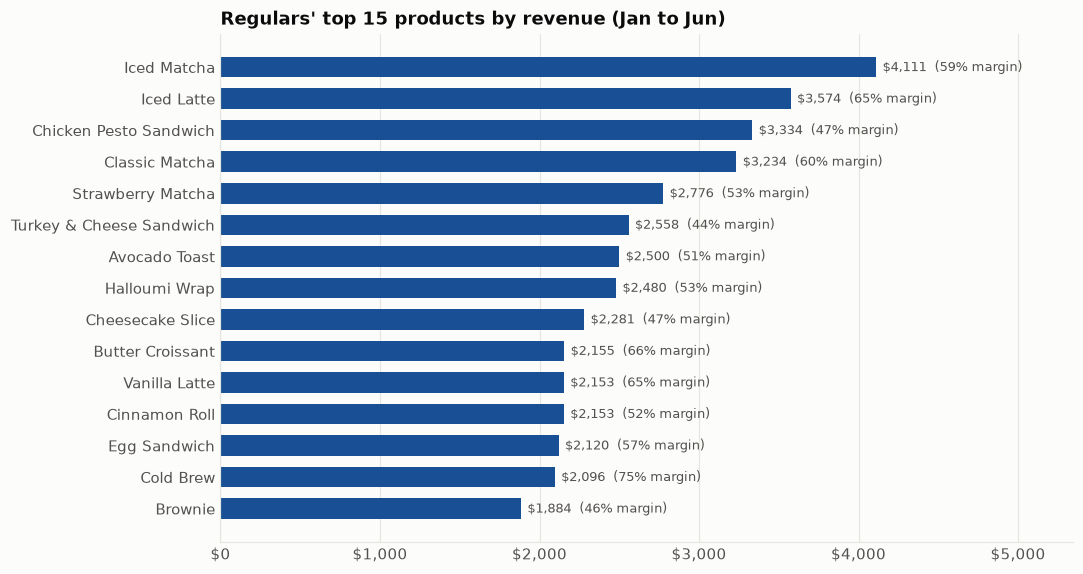

Product,Category,units,revenue,profit,margin,share of regulars' revenue
Iced Matcha,Matcha & Tea,593,"$4,111","$2,439",59%,5.1%
Iced Latte,Cold Coffee,665,"$3,574","$2,327",65%,4.5%
Chicken Pesto Sandwich,Sandwiches,309,"$3,334","$1,555",47%,4.2%
Classic Matcha,Matcha & Tea,495,"$3,234","$1,945",60%,4.0%
Strawberry Matcha,Matcha & Tea,360,"$2,776","$1,474",53%,3.5%
Turkey & Cheese Sandwich,Sandwiches,265,"$2,558","$1,135",44%,3.2%
Avocado Toast,Breakfast,262,"$2,500","$1,271",51%,3.1%
Halloumi Wrap,Sandwiches,249,"$2,480","$1,315",53%,3.1%
Cheesecake Slice,Desserts,337,"$2,281","$1,074",47%,2.9%
Butter Croissant,Bakery,582,"$2,155","$1,413",66%,2.7%


In [2]:
reg = lines[lines["segment"] == "Regular"]
top = reg.groupby(["Product", "Category"]).agg(units=("Quantity", "sum"), revenue=(R, "sum"),
                                               profit=(GP, "sum")).reset_index()
top["margin"] = top["profit"] / top["revenue"]
top["share of regulars' revenue"] = top["revenue"] / top["revenue"].sum()
top = top.sort_values("revenue", ascending=False)

fig, ax = plt.subplots(figsize=(10, 6))
t = top.head(15).iloc[::-1]
ax.barh(t["Product"], t["revenue"], color=SEG_COLORS["Regular"], height=0.65)
for i, (v, m) in enumerate(zip(t["revenue"], t["margin"])):
    ax.text(v + 40, i, f"${v:,.0f}  ({m:.0%} margin)", va="center", color=INK2, fontsize=8.5)
ax.xaxis.set_major_formatter(mtick.StrMethodFormatter("${x:,.0f}"))
ax.set_xlim(0, t["revenue"].max() * 1.3)
ax.set_title("Regulars' top 15 products by revenue (Jan to Jun)")
ax.grid(axis="y", visible=False)
plt.show()

top.head(10).style.format({"units": "{:,.0f}", "revenue": "${:,.0f}", "profit": "${:,.0f}", "margin": "{:.0%}",
                           "share of regulars' revenue": "{:.1%}"}).hide(axis="index")

In [3]:
mix = pd.crosstab(lines["Category"], lines["segment"], values=lines["Quantity"], aggfunc="sum", normalize="columns")[SEGMENTS]
mix["Regular vs others (points)"] = (mix["Regular"] - lines[lines["segment"] != "Regular"].groupby("Category")["Quantity"].sum()
                                     .pipe(lambda s: s / s.sum())) * 100
mix.sort_values("Regular", ascending=False).style.format("{:.1%}").format("{:+.1f}", subset=["Regular vs others (points)"])

segment,Regular,Occasional,Rare,Regular vs others (points)
Category,,,,
Bakery,22.3%,21.1%,20.3%,+1.3
Hot Coffee,15.9%,15.8%,15.9%,+0.1
Matcha & Tea,14.2%,15.0%,15.6%,-0.9
Cold Coffee,14.0%,14.6%,15.0%,-0.7
Cold Drinks,10.4%,9.9%,9.2%,+0.5
Desserts,8.8%,8.7%,8.9%,+0.0
Sandwiches,7.2%,7.3%,6.8%,-0.1
Breakfast,4.7%,4.5%,5.5%,+0.1
Meals,2.6%,3.0%,2.9%,-0.4


**Takeaway:** regulars spend most on **Iced Matcha, Iced Latte, Chicken Pesto Sandwich, Classic Matcha and Strawberry Matcha**. Butter Croissant is their third most bought item by units but cheap, so it ranks lower by revenue. Their category mix is within about 1 percentage point of other customers' in every category: bakery slightly higher for regulars (+1.3 points), matcha (-0.9) and cold coffee (-0.7) slightly lower.

## 3. Products regulars buy more or less than other customers

For each product we compare its share of regulars' units with its share of other customers' units. An **index of 1.10** means the product makes up 10% more of regulars' purchases than of other customers' purchases.

The gray band shows how far the index can move **by chance alone**: we shuffle which customers count as regulars (keeping the same number of regulars) 300 times and take the middle 95% of results for each product.

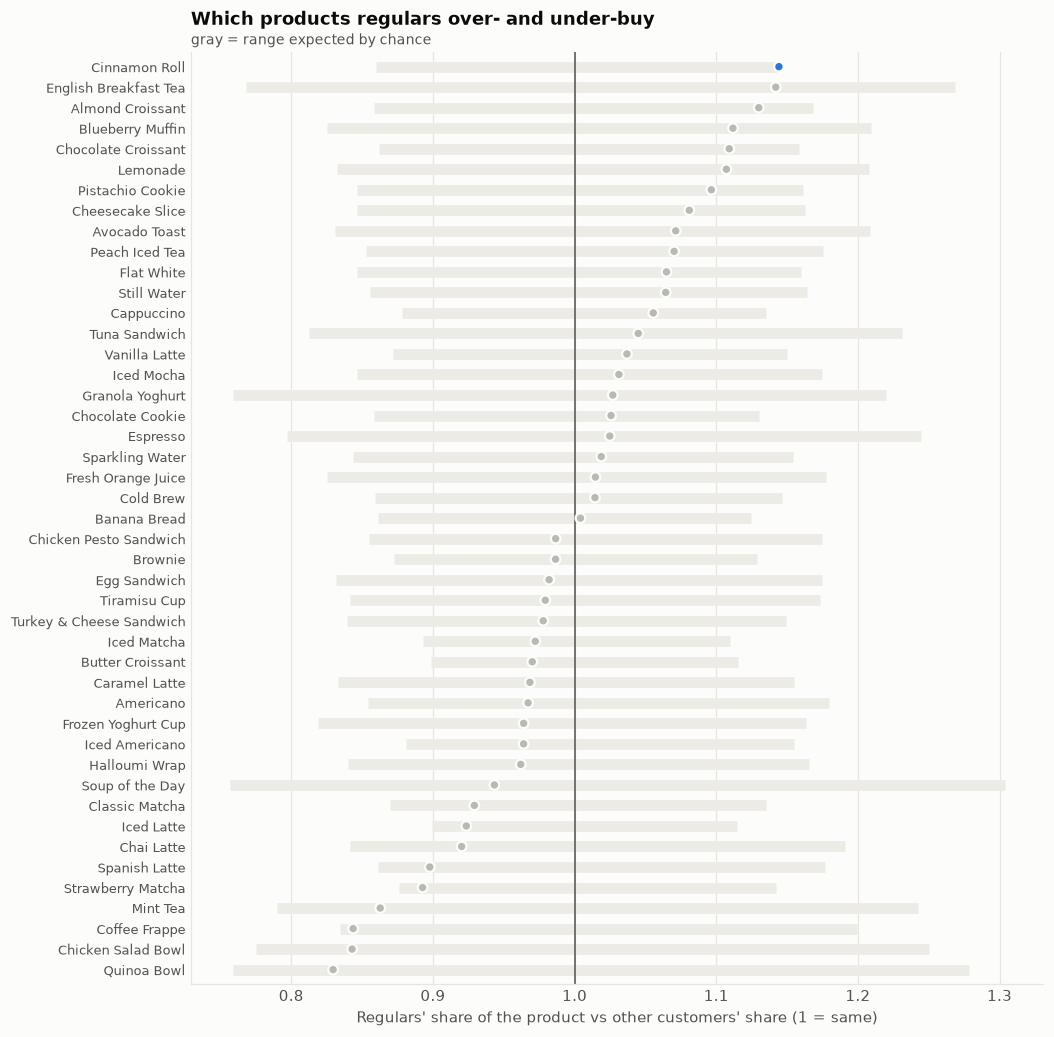

Products outside the chance range: 1 of 45 (about 2 would be expected by luck alone)


,index,chance low,chance high,outside chance?
Product,,,,
Cinnamon Roll,1.14,0.86,1.14,more


In [4]:
def regular_index(seg_of_customer):
    """Product share among regulars / product share among everyone else (units)."""
    is_reg = lines["Customer ID"].map(seg_of_customer).eq("Regular")
    reg_u = lines[is_reg].groupby("Product")["Quantity"].sum()
    oth_u = lines[~is_reg].groupby("Product")["Quantity"].sum()
    return (reg_u / reg_u.sum()) / (oth_u / oth_u.sum())


actual = regular_index(cust["segment"])
null = pd.DataFrame([regular_index(pd.Series(rng.permutation(cust["segment"].values), index=cust.index))
                     for _ in range(N_SHUFFLES)])
lo, hi = null.quantile(0.025), null.quantile(0.975)
idx = pd.DataFrame({"index": actual, "chance low": lo, "chance high": hi}).sort_values("index")
idx["outside chance?"] = np.where(idx["index"] > idx["chance high"], "more", np.where(idx["index"] < idx["chance low"], "less", ""))

fig, ax = plt.subplots(figsize=(10, 11))
y = np.arange(len(idx))
ax.hlines(y, idx["chance low"], idx["chance high"], color=BAND, lw=7, zorder=1)
colors = [ACCENT if f == "more" else NEG if f == "less" else MUTED for f in idx["outside chance?"]]
ax.scatter(idx["index"], y, color=colors, s=40, zorder=3, edgecolors=SURFACE, linewidths=1.5)
ax.axvline(1, color=INK2, lw=1)
ax.set_yticks(y, idx.index, fontsize=8.5)
ax.set_xlabel("Regulars' share of the product vs other customers' share (1 = same)")
ax.set_title("Which products regulars over- and under-buy", pad=18)
ax.text(0, 1.005, "gray = range expected by chance", transform=ax.transAxes, color=INK2, fontsize=9, va="bottom")
ax.grid(axis="y", visible=False)
ax.set_ylim(-0.7, len(idx) - 0.3)
plt.show()

print(f"Products outside the chance range: {(idx['outside chance?'] != '').sum()} of {len(idx)} "
      f"(about {0.05 * len(idx):.0f} would be expected by luck alone)")
idx[idx["outside chance?"] != ""].style.format("{:.2f}", subset=["index", "chance low", "chance high"])

**How to read it:** blue dots are products regulars buy **more** than chance would explain, red dots **less**, gray dots are within normal variation.

**Takeaway:** **regulars buy the same products as everyone else.** Only one product (Cinnamon Roll, right at the edge of its band) falls outside the chance range, fewer than the two you'd expect by luck alone. The dots do lean slightly toward pastries at the top (Cinnamon Roll, Almond Croissant, Blueberry Muffin, Chocolate Croissant) and bowls and specialty drinks at the bottom (Quinoa Bowl, Chicken Salad Bowl, Coffee Frappe), matching the small bakery tilt in section 2, but none of it is strong enough to act on. There's no case for a separate "regulars' menu".

## 4. Which products depend most on regulars

Regulars bring in about **26% of all revenue** (including anonymous walk-ins). Some products get more of their revenue from regulars than others, which matters if regulars start slipping away (see `04_regular_customers`, section 9).

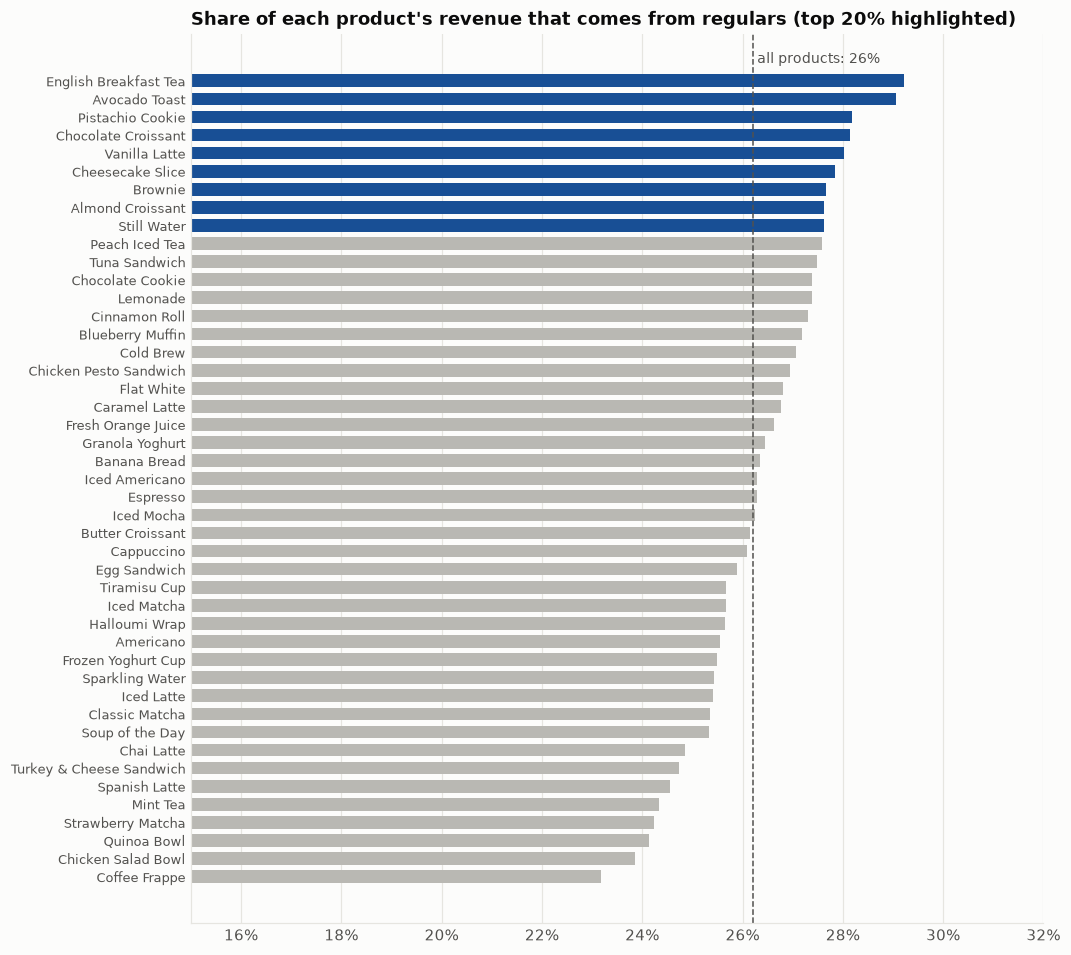

,share of revenue from regulars
Product,
English Breakfast Tea,29.2%
Avocado Toast,29.1%
Pistachio Cookie,28.2%
Chocolate Croissant,28.1%
Vanilla Latte,28.0%
Cheesecake Slice,27.8%
Brownie,27.7%
Almond Croissant,27.6%
Still Water,27.6%


In [5]:
prod_seg = df.pivot_table(index="Product", columns="segment", values=R, aggfunc="sum").fillna(0)
dep = (prod_seg["Regular"] / prod_seg.sum(axis=1)).sort_values()
overall = prod_seg["Regular"].sum() / prod_seg.values.sum()

fig, ax = plt.subplots(figsize=(10, 10.5))
ax.barh(dep.index, dep.values, color=[SEG_COLORS["Regular"] if v >= dep.quantile(0.8) else MUTED for v in dep.values],
        height=0.7)
ax.axvline(overall, color=INK2, ls="--", lw=1)
ax.text(overall, len(dep) - 0.2, f" all products: {overall:.0%}", color=INK2, va="bottom", fontsize=9)
ax.xaxis.set_major_formatter(pct)
ax.set_xlim(0.15, 0.32)
ax.tick_params(axis="y", labelsize=8.5)
ax.set_title("Share of each product's revenue that comes from regulars (top 20% highlighted)")
ax.grid(axis="y", visible=False)
plt.show()
dep.sort_values(ascending=False).head(9).rename("share of revenue from regulars").to_frame().style.format("{:.1%}")

**Takeaway:** every product gets between about **23% and 29%** of its revenue from regulars, a narrow range given that section 3 found no real difference in what regulars buy. The top of the list (English Breakfast Tea, Avocado Toast, Pistachio Cookie, Chocolate Croissant) is mostly noise. **No product depends on regulars much more than the others**, so losing regulars would hit sales across the whole menu, not one product line.

## 5. Gateway products: does the first purchase predict becoming a regular?

For each product, we look at customers whose **first ever order** included it and check what share of them ended up as regulars. The overall rate is about 30%. Error bars show the 95% range expected by chance for that number of customers: products with few first-time buyers have wide bars.

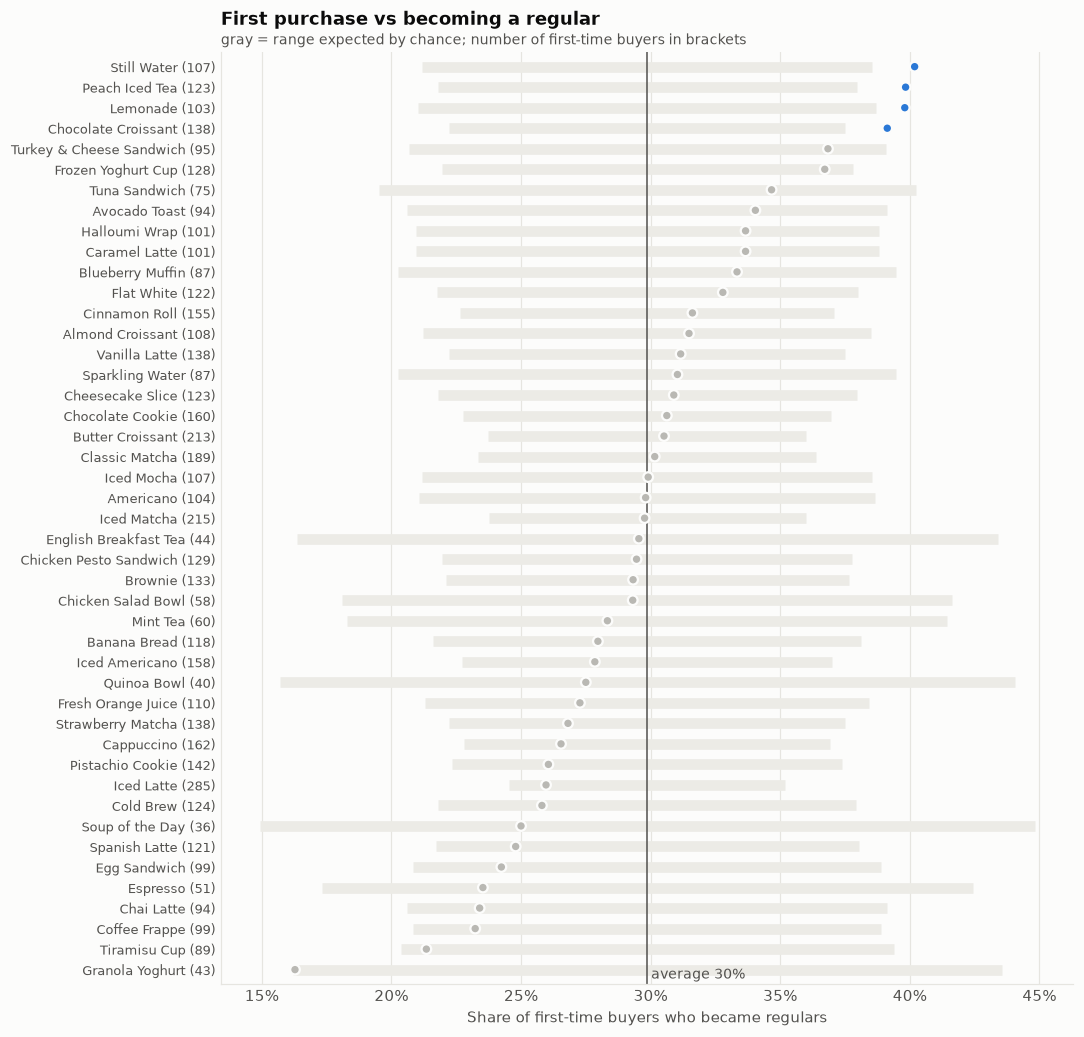

Products outside the chance range: 4 of 45 (about 2 would be expected by luck alone)


,first-time buyers,became regular,chance ±,outside chance?
Product,,,,
Chocolate Croissant,138,39%,±8%,higher
Lemonade,103,40%,±9%,higher
Peach Iced Tea,123,40%,±8%,higher
Still Water,107,40%,±9%,higher


In [6]:
first_order = lines.sort_values("Date").groupby("Customer ID")["Transaction ID"].first()
first_lines = lines[lines["Transaction ID"].isin(first_order.values)]
gate = first_lines.groupby("Product")["Customer ID"].agg(lambda s: list(s.unique()))
gate = pd.DataFrame({
    "first-time buyers": gate.str.len(),
    "became regular": gate.apply(lambda ids: (cust.loc[ids, "segment"] == "Regular").mean()),
})
base = (cust["segment"] == "Regular").mean()
gate["chance ±"] = 1.96 * np.sqrt(base * (1 - base) / gate["first-time buyers"])
gate["outside chance?"] = np.where(gate["became regular"] - base > gate["chance ±"], "higher",
                                   np.where(base - gate["became regular"] > gate["chance ±"], "lower", ""))
gate = gate.sort_values("became regular")

fig, ax = plt.subplots(figsize=(10, 11))
y = np.arange(len(gate))
ax.hlines(y, base - gate["chance ±"], base + gate["chance ±"], color=BAND, lw=7, zorder=1)
colors = [ACCENT if f == "higher" else NEG if f == "lower" else MUTED for f in gate["outside chance?"]]
ax.scatter(gate["became regular"], y, color=colors, s=40, zorder=3, edgecolors=SURFACE, linewidths=1.5)
ax.axvline(base, color=INK2, lw=1)
ax.text(base, -0.6, f" average {base:.0%}", color=INK2, va="bottom", fontsize=9)
ax.set_yticks(y, [f"{p} ({n})" for p, n in zip(gate.index, gate["first-time buyers"])], fontsize=8.5)
ax.xaxis.set_major_formatter(pct)
ax.set_xlabel("Share of first-time buyers who became regulars")
ax.set_title("First purchase vs becoming a regular", pad=18)
ax.text(0, 1.005, "gray = range expected by chance; number of first-time buyers in brackets", transform=ax.transAxes,
        color=INK2, fontsize=9, va="bottom")
ax.grid(axis="y", visible=False)
ax.set_ylim(-0.7, len(gate) - 0.3)
plt.show()

print(f"Products outside the chance range: {(gate['outside chance?'] != '').sum()} of {len(gate)} "
      f"(about {0.05 * len(gate):.0f} would be expected by luck alone)")
gate[gate["outside chance?"] != ""].style.format({"became regular": "{:.0%}", "chance ±": "±{:.0%}"})

**Takeaway:** what a customer buys first **barely predicts** whether they become a regular. Rates run from about 16% (Granola Yoghurt) to 40% (Still Water), and 41 of 45 products are inside their chance range. Four sit just above it: **Still Water, Peach Iced Tea, Lemonade (all cold drinks) and Chocolate Croissant**, at about 40% vs the 30% average. With 45 products you'd expect about 2 to land outside by luck, so 4 is only a weak lead. If the team wants to test it, a "first visit: free lemonade or iced tea with any pastry" offer is cheap, but don't promise that it creates regulars.

## 6. Do regulars have a "usual"?

If regulars had a usual order, a large share of their visits would include the same product. We measure, for each regular, the **share of their orders that include their most-bought product**, and compare it with what you'd get if their products were **picked at random** (we shuffle products across all regulars' order lines, keeping order sizes).

We also count **how many different products** each regular has tried.

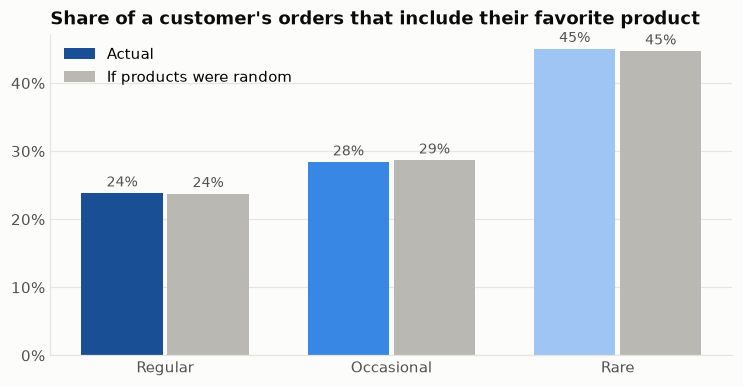

,orders with their favorite product,same if products were random,different products tried (median),orders per customer (median)
segment,,,,
Regular,24%,24%,11,9
Occasional,28%,29%,8,6
Rare,45%,45%,4,3


In [7]:
def favorite_share(frame):
    """Per customer: share of their orders containing their single most frequent product."""
    per = frame.groupby(["Customer ID", "Product"])["Transaction ID"].nunique()
    fav = per.groupby(level=0).max()
    n = frame.groupby("Customer ID")["Transaction ID"].nunique()
    return (fav / n)


rows = []
for seg in SEGMENTS:
    seg_lines = lines[lines["segment"] == seg][["Customer ID", "Transaction ID", "Product"]]
    actual_share = favorite_share(seg_lines).mean()
    shuffled = []
    for _ in range(30):
        sh = seg_lines.copy()
        sh["Product"] = rng.permutation(sh["Product"].values)
        shuffled.append(favorite_share(sh).mean())
    tried = seg_lines.groupby("Customer ID")["Product"].nunique()
    rows.append({"segment": seg, "orders with their favorite product": actual_share,
                 "same if products were random": np.mean(shuffled),
                 "different products tried (median)": tried.median(),
                 "orders per customer (median)": seg_lines.groupby("Customer ID")["Transaction ID"].nunique().median()})
usual = pd.DataFrame(rows).set_index("segment")

fig, ax = plt.subplots(figsize=(8, 3.8))
x = np.arange(len(SEGMENTS))
ax.bar(x - 0.19, usual["orders with their favorite product"], width=0.36, color=[SEG_COLORS[s] for s in SEGMENTS],
       label="Actual")
ax.bar(x + 0.19, usual["same if products were random"], width=0.36, color=MUTED, label="If products were random")
for xi, (a, r) in enumerate(usual[["orders with their favorite product", "same if products were random"]].values):
    ax.text(xi - 0.19, a + 0.01, f"{a:.0%}", ha="center", color=INK2, fontsize=9)
    ax.text(xi + 0.19, r + 0.01, f"{r:.0%}", ha="center", color=INK2, fontsize=9)
ax.set_xticks(x, SEGMENTS)
ax.yaxis.set_major_formatter(pct)
ax.set_title("Share of a customer's orders that include their favorite product")
ax.legend(loc="upper left")
ax.grid(axis="x", visible=False)
plt.show()
usual.style.format({"orders with their favorite product": "{:.0%}", "same if products were random": "{:.0%}",
                    "different products tried (median)": "{:.0f}", "orders per customer (median)": "{:.0f}"})

**Takeaway:** regulars **don't have a usual**. Their favorite product shows up in about a quarter of their orders, which is no more than if they picked products at random. The typical regular has tried about **11 different products in 9 visits**. This confirms the team's pitch finding (no personal "usual" to target) and means:
- "Your usual?" style personalization won't work on this data;
- regulars are an **easy audience for new items**, because they already rotate through the menu.

## 7. Does what regulars buy change as they keep coming?

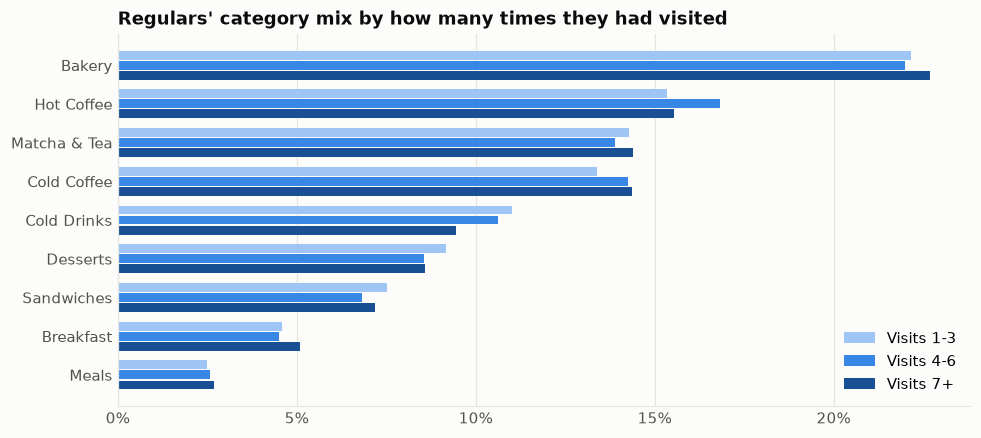

,order value,items per order
stage,,
Visits 1-3,$9.04,1.61
Visits 4-6,$8.79,1.57
Visits 7+,$9.09,1.60


In [8]:
r = lines[lines["segment"] == "Regular"].copy()
visit_no = r[["Customer ID", "Transaction ID", "Date"]].drop_duplicates("Transaction ID").sort_values("Date")
visit_no["visit"] = visit_no.groupby("Customer ID").cumcount() + 1
r = r.merge(visit_no[["Transaction ID", "visit"]], on="Transaction ID")
r["stage"] = pd.cut(r["visit"], [0, 3, 6, 100], labels=["Visits 1-3", "Visits 4-6", "Visits 7+"])

stage_mix = pd.crosstab(r["Category"], r["stage"], values=r["Quantity"], aggfunc="sum", normalize="columns")
stage_basket = r.groupby(["stage", "Transaction ID"], observed=True).agg(rev=(R, "sum"), items=("Quantity", "sum")) \
                .groupby("stage", observed=True).mean()

fig, ax = plt.subplots(figsize=(10, 4.4))
stage_order = stage_mix.sort_values("Visits 1-3", ascending=False)
yy = np.arange(len(stage_order))
h = 0.26
for i, (stage, c) in enumerate(zip(stage_mix.columns, ["#9ec5f4", "#3987e5", "#184f95"])):
    ax.barh(yy + (i - 1) * h, stage_order[stage], height=h - 0.03, color=c, label=stage)
ax.set_yticks(yy, stage_order.index)
ax.invert_yaxis()
ax.xaxis.set_major_formatter(pct)
ax.set_title("Regulars' category mix by how many times they had visited")
ax.legend(loc="lower right")
ax.grid(axis="y", visible=False)
plt.show()
stage_basket.rename(columns={"rev": "order value", "items": "items per order"}).style.format(
    {"order value": "${:.2f}", "items per order": "{:.2f}"})

**Takeaway:** a regular's 10th visit looks like their 1st. The category mix moves by about 1 point or less between early and later visits, and order value ($9.04 → $8.79 → $9.09) and items per order (about 1.6) stay flat. Regulars don't "trade up" to bigger orders on their own, so growing their basket needs an active push (bundles, add-on at the till).

## 8. What regulars buy together

Orders with 2+ different products: regulars 47%, other identified customers 46%


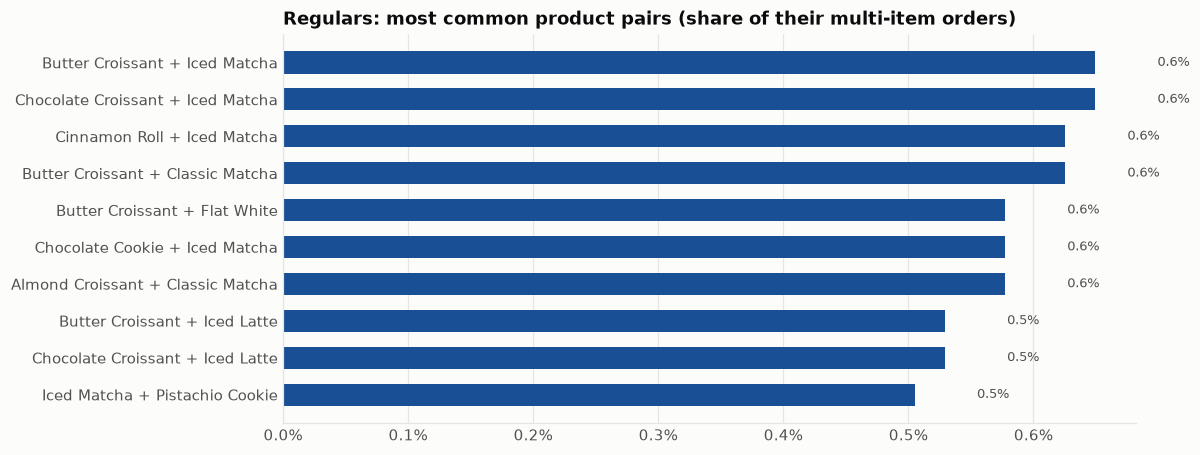

pair,orders,share of multi-item orders
Butter Croissant + Iced Matcha,27,0.6%
Chocolate Croissant + Iced Matcha,27,0.6%
Cinnamon Roll + Iced Matcha,26,0.6%
Butter Croissant + Classic Matcha,26,0.6%
Butter Croissant + Flat White,24,0.6%
Chocolate Cookie + Iced Matcha,24,0.6%
Almond Croissant + Classic Matcha,24,0.6%
Butter Croissant + Iced Latte,22,0.5%
Chocolate Croissant + Iced Latte,22,0.5%
Iced Matcha + Pistachio Cookie,21,0.5%


In [9]:
def top_pairs(frame, n=10):
    baskets = frame.groupby("Transaction ID")["Product"].apply(lambda s: tuple(sorted(set(s))))
    multi = baskets[baskets.str.len() >= 2]
    counts = Counter(p for t in multi for p in combinations(t, 2))
    return pd.DataFrame([(f"{a} + {b}", c, c / len(multi)) for (a, b), c in counts.most_common(n)],
                        columns=["pair", "orders", "share of multi-item orders"]), len(multi) / len(baskets)


reg_pairs, reg_multi = top_pairs(lines[lines["segment"] == "Regular"])
oth_pairs, oth_multi = top_pairs(lines[lines["segment"] != "Regular"])
print(f"Orders with 2+ different products: regulars {reg_multi:.0%}, other identified customers {oth_multi:.0%}")

fig, ax = plt.subplots(figsize=(10, 4.6))
t = reg_pairs.iloc[::-1]
ax.barh(t["pair"], t["share of multi-item orders"], color=SEG_COLORS["Regular"], height=0.6)
for i, v in enumerate(t["share of multi-item orders"]):
    ax.text(v + 0.0005, i, f"{v:.1%}", va="center", color=INK2, fontsize=8.5)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=1))
ax.set_title("Regulars: most common product pairs (share of their multi-item orders)")
ax.grid(axis="y", visible=False)
plt.show()
reg_pairs.style.format({"share of multi-item orders": "{:.1%}"}).hide(axis="index")

**Takeaway:** regulars combine products the same way as everyone else: a **matcha or iced latte with a pastry** (Butter Croissant, Chocolate Croissant, Cinnamon Roll, Chocolate Cookie). 47% of their orders contain two or more different products, vs 46% for other customers, so they aren't bigger basket-builders either. A "matcha + pastry" bundle on a loyalty card would match what regulars already do.

## 9. Regulars' favorite products by branch

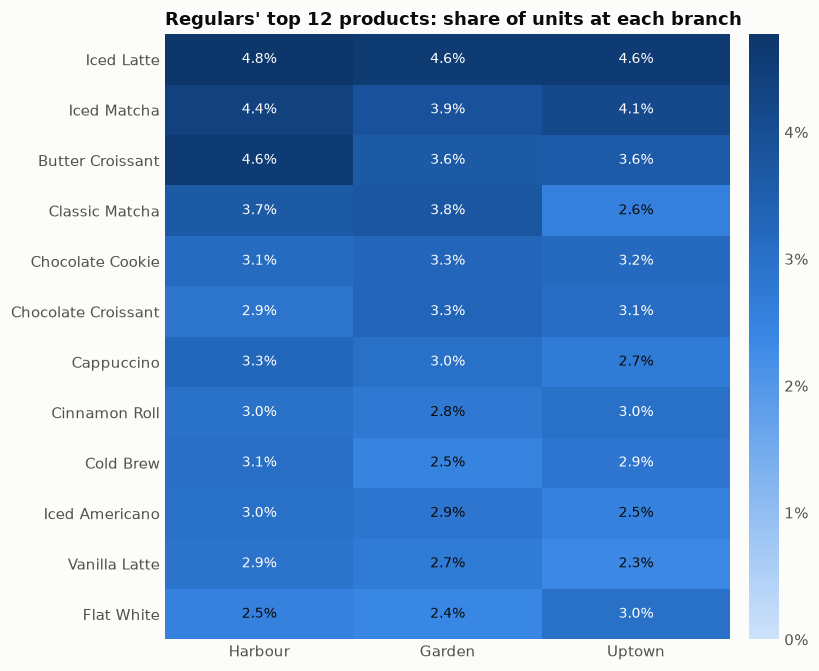

In [10]:
rb = lines[lines["segment"] == "Regular"].groupby(["Branch", "Product"])["Quantity"].sum()
rb = rb / rb.groupby(level=0).transform("sum")
top_by_branch = rb.unstack(0)[BRANCHES]
show = top_by_branch.mean(axis=1).sort_values(ascending=False).head(12).index
t = top_by_branch.loc[show]

fig, ax = plt.subplots(figsize=(7.5, 6.2))
im = ax.imshow(t.values, cmap=LinearSegmentedColormap.from_list("seq", SEQ), aspect="auto", vmin=0)
ax.set_xticks(range(len(BRANCHES)), BRANCHES)
ax.set_yticks(range(len(t)), t.index)
ax.grid(False)
for s_ in ax.spines.values():
    s_.set_visible(False)
for i in range(t.shape[0]):
    for j in range(t.shape[1]):
        v = t.iat[i, j]
        ax.text(j, i, f"{v:.1%}", ha="center", va="center", fontsize=9, color="white" if v > t.values.max() * 0.6 else INK)
cb = fig.colorbar(im, ax=ax, fraction=0.05, pad=0.03, format=mtick.PercentFormatter(1.0, decimals=0))
cb.outline.set_visible(False)
ax.set_title("Regulars' top 12 products: share of units at each branch")
plt.tight_layout()
plt.show()

**Takeaway:** regulars' favorites are the same at all three branches: Iced Latte, Iced Matcha and Butter Croissant are the top three everywhere. Most products are within about 1 point across branches; the biggest gaps are Butter Croissant (4.6% at Harbour vs 3.6% elsewhere) and Classic Matcha (2.6% at Uptown vs about 3.8% elsewhere). A single loyalty offer can work across the whole chain.

## 10. Conclusion and business ideas

| Finding | Evidence | Business idea |
|---|---|---|
| **Regulars buy what everyone buys** | Category mix within about 1 point of other customers; only 1 of 45 products outside the chance range | No need for a separate "regulars' menu" |
| **A slight pastry tilt** | Bakery +1.3 points for regulars; pastries at the top of the index, but within chance | Pastries are a natural loyalty reward (for example a free pastry after 8 visits) |
| **No product depends on regulars** | Every product gets 23-29% of its revenue from regulars | Losing regulars would hit the whole menu, not one product line |
| **No reliable gateway product** | 41 of 45 first purchases inside the chance range; cold drinks and Chocolate Croissant slightly higher (weak lead) | Focus on getting first-timers back; test a cheap cold-drink offer on first visits if you want |
| **Regulars have no "usual"** | Favorite product in about a quarter of orders, same as random; about 11 products tried in 9 visits | Skip "your usual" personalization; use regulars to launch new items |
| **They don't trade up on their own** | Order value and mix flat from visit 1 to visit 7+ | Push bundles and till add-ons actively |
| **Matcha/latte + pastry is the natural pair** | Top pairs among regulars | A matcha + pastry bundle on the loyalty card |
| **Same favorites at every branch** | Top products match across branches | One chain-wide offer |

*The data is synthetic, so product choices may be more random and uniform than in a real café.*